### 4.1.3 Scenario #2
**Second scenario:** "Design a 3-department campus with Finance, Sales, and IT."

As part of the process, the planning agent clarified requirements from the user. We observed that while the agent successfully generated topologies when users provided explicit setup details (clear requirements), it failed when users asked for recommendations (unclear requirements).

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


# Load data
df = pd.read_csv('scenario_runs.csv')
df.head()

,Run #,Requirements Clear?,Questions Asked?,Design Generated?,Retries,Runtime (Seconds),Result
0,1,No,1,No,0,2.704,Needs Clarification
1,2,No,1,No,0,1.123,Needs Clarification
2,3,No,1,No,0,1.242,Needs Clarification
3,4,No,1,No,0,1.584,Needs Clarification
4,5,No,0,No,0,5.446,Error: 'NoneType' object has no attribute 'nodes'


#### Analysis of Result Outcomes Based on Clarity of Requirements

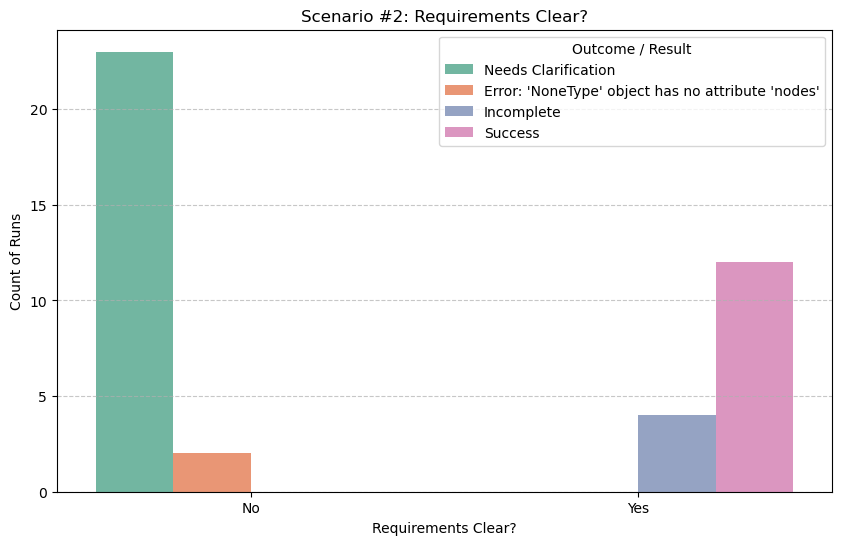

In [2]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Requirements Clear?', hue='Result', palette='Set2')
plt.title('Scenario #2: Requirements Clear?')
plt.ylabel('Count of Runs')
plt.legend(title='Outcome / Result')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Analysis of Result Outcomes Based on Questions Asked?

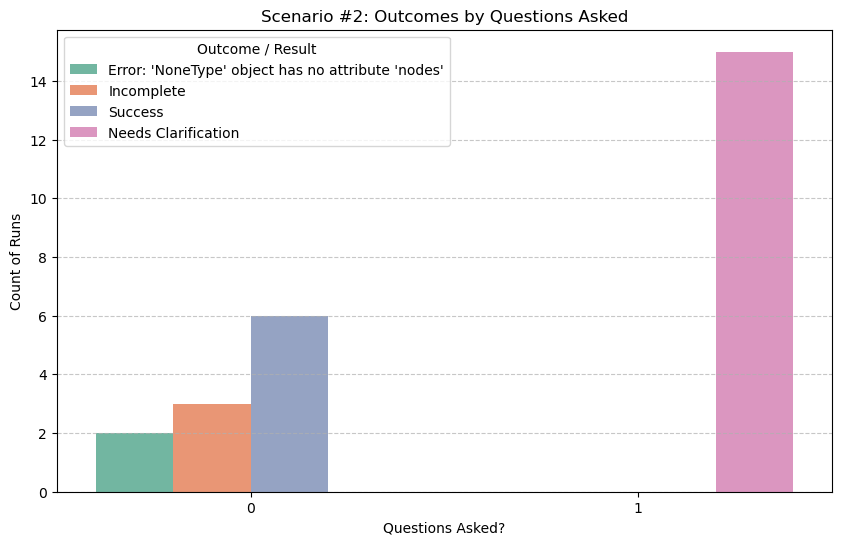

In [6]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Questions Asked?', hue='Result', palette='Set2')
plt.title('Scenario #2: Outcomes by Questions Asked')
plt.ylabel('Count of Runs')
plt.legend(title='Outcome / Result')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Topology Generation Success Rate
We consider success to be when the `Design Generated?` feature evaluates to `Yes`.

C:\Users\96653\AppData\Local\Temp\ipykernel_23364\277777406.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=success_stats, x='Requirements Clear?', y='Success Rate (%)', palette='viridis')


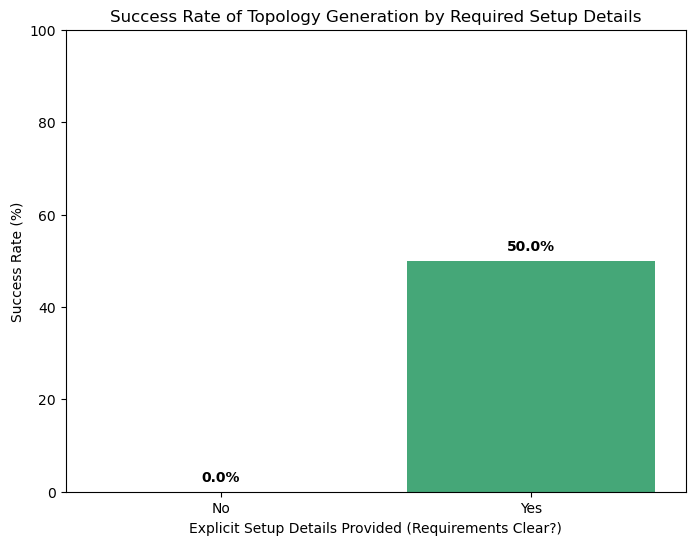

In [3]:
# Calculate success rate
df['Success'] = df['Design Generated?'] == 'Yes'
success_stats = df.groupby('Requirements Clear?')['Success'].agg(['count', 'mean']).reset_index()
success_stats['Success Rate (%)'] = success_stats['mean'] * 100

plt.figure(figsize=(8, 6))
ax = sns.barplot(data=success_stats, x='Requirements Clear?', y='Success Rate (%)', palette='viridis')
plt.title('Success Rate of Topology Generation by Required Setup Details')
plt.xlabel('Explicit Setup Details Provided (Requirements Clear?)')
plt.ylabel('Success Rate (%)')
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10),
                textcoords='offset points', fontweight='bold')

plt.show()

### 4.1.3 Scenario #4
**Second scenario:** "Design a 4-department SME with 50 users each"

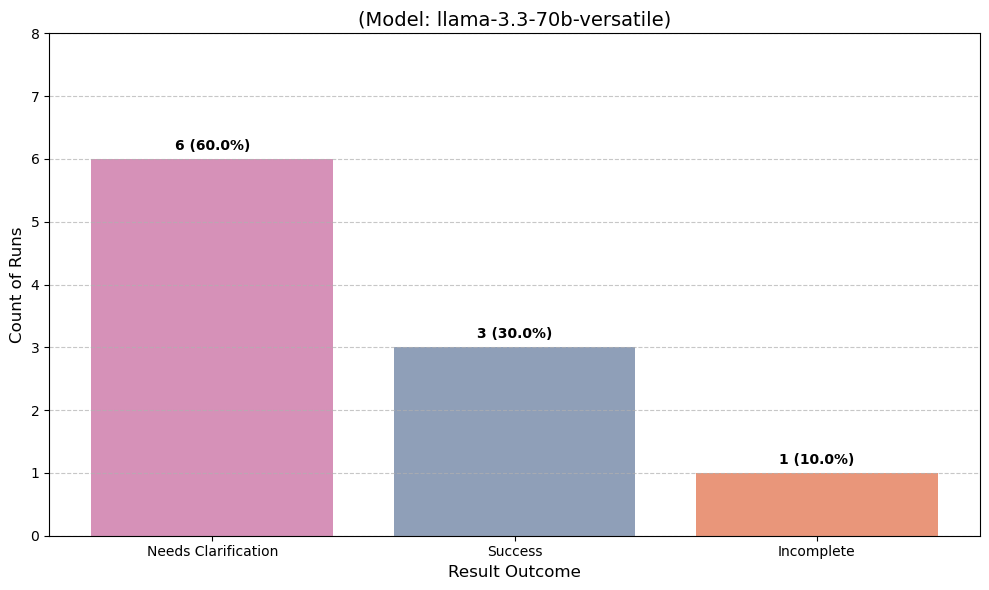

In [ ]:

data = {
    'Run #': [32, 33, 34, 35, 36, 37, 38, 39, 40, 41],
    'Result': [
        'Needs Clarification', 'Needs Clarification', 'Success', 
        'Needs Clarification', 'Needs Clarification', 'Success', 
        'Incomplete', 'Needs Clarification', 'Needs Clarification', 'Success'
    ]
}

df = pd.DataFrame(data)

# Calculate counts and percentages
result_counts = df['Result'].value_counts()
labels = result_counts.index
values = result_counts.values
percentages = (result_counts / len(df) * 100).round(1)

# Plot
plt.figure(figsize=(10, 6))
colors = ['#d691b8', '#8f9fb8', '#e9967a'] 
bars = plt.bar(labels, values, color=colors)

# Add value labels on top of bars
for bar, pct in zip(bars, percentages):
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2, 
        yval + 0.1, 
        f'{int(yval)} ({pct}%)', 
        ha='center', 
        va='bottom', 
        fontweight='bold'
    )

# Formatting
plt.title('(Model: llama-3.3-70b-versatile)', fontsize=14)
plt.xlabel('Result Outcome', fontsize=12)
plt.ylabel('Count of Runs', fontsize=12)
plt.ylim(0, 8)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Part Analysis

## Agent Trace of Recovered Scenario 4 Run

Scenario 4: *"Design a 4-department SME with 50 users each."*

Part 1 **run 38** (`scenario_runs.csv`): requirements were clear, but topology generation failed after a single Groq attempt (`Result = Incomplete`, 4.681 s). Part 2 adds a topology retry edge and GPT-5.5 escalation. A recovered run of the same class (`scenario_runs_part2.csv` run 38: `Success`, `Topology Source = openai_escalated`, `Topology Retries = 1`, 40.065 s) completes after the primary attempt is rejected.

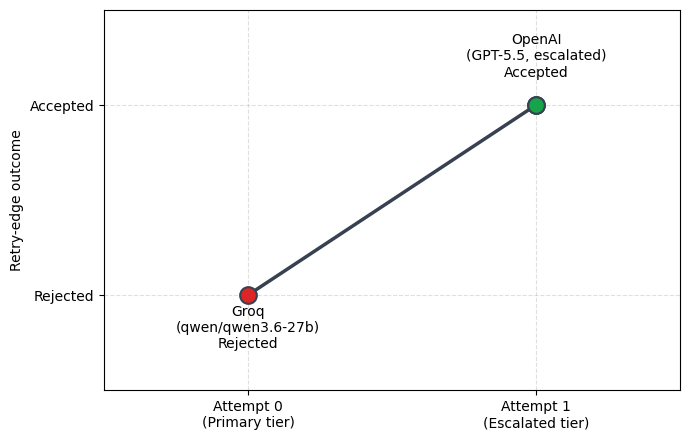

In [20]:

# Data from scenario_runs_part2.csv, Run 38
attempts = [0, 1]
outcome = [0, 1]  # 0 = Rejected, 1 = Accepted
models = ["Groq\n(qwen/qwen3.6-27b)", "OpenAI\n(GPT-5.5, escalated)"]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(attempts, outcome, marker='o', markersize=12, linewidth=2.5,
        color='#374151', markerfacecolor='#DC2626', markeredgecolor='#374151',
        markeredgewidth=1.5, zorder=3)

ax.plot(1, 1, marker='o', markersize=12, color='#16A34A',
        markeredgecolor='#374151', markeredgewidth=1.5, zorder=4)

ax.annotate(f"{models[0]}\nRejected", xy=(0, 0), xytext=(0, -0.28),
            ha='center', fontsize=10)
ax.annotate(f"{models[1]}\nAccepted", xy=(1, 1), xytext=(1, 1.15),
            ha='center', fontsize=10)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Attempt 0\n(Primary tier)", "Attempt 1\n(Escalated tier)"], fontsize=10)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Rejected", "Accepted"], fontsize=10)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)

ax.set_ylabel("Retry-edge outcome", fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)

# ax.set_title("Design a 4-department SME with 50 users each\n",
#               fontsize=11, weight='bold')

plt.tight_layout()
plt.show()

### Topology escalated-tier trade-off (wall-clock, reasoning tokens, cost)

###### Source: Source data are in findings.md ("Topology escalated: medium vs low, 4 sizes x 2 efforts x 3 reps").


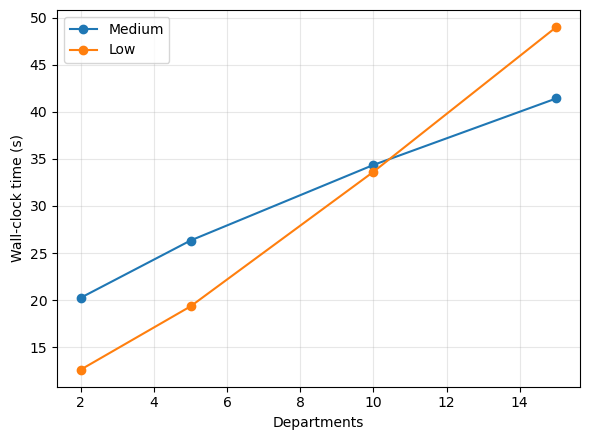

In [16]:

df = pd.DataFrame({
    "departments": [2, 5, 10, 15],
    "medium": [20.26, 26.33, 34.35, 41.41],
    "low":    [12.63, 19.34, 33.62, 48.98],
})

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(df.departments, df.medium, marker='o', label='Medium')
ax.plot(df.departments, df.low, marker='o', label='Low')
ax.set_xlabel("Departments")
ax.set_ylabel("Wall-clock time (s)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

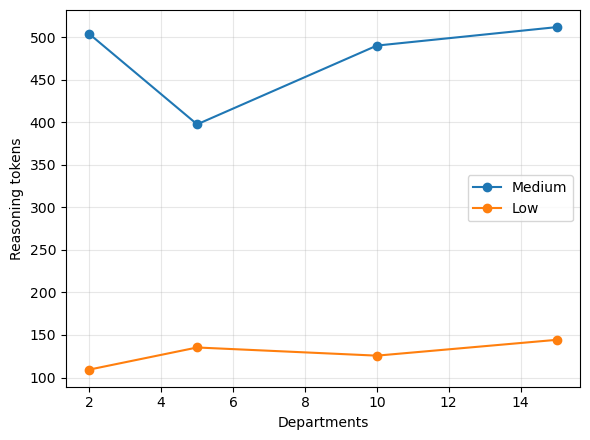

In [17]:


df = pd.DataFrame({
    "departments": [2, 5, 10, 15],
    "medium": [504.0, 397.7, 490.3, 512.0],
    "low":    [109.3, 135.3, 125.7, 144.3],
})

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(df.departments, df.medium, marker='o', label='Medium')
ax.plot(df.departments, df.low, marker='o', label='Low')
ax.set_xlabel("Departments")
ax.set_ylabel("Reasoning tokens")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

plt.show()

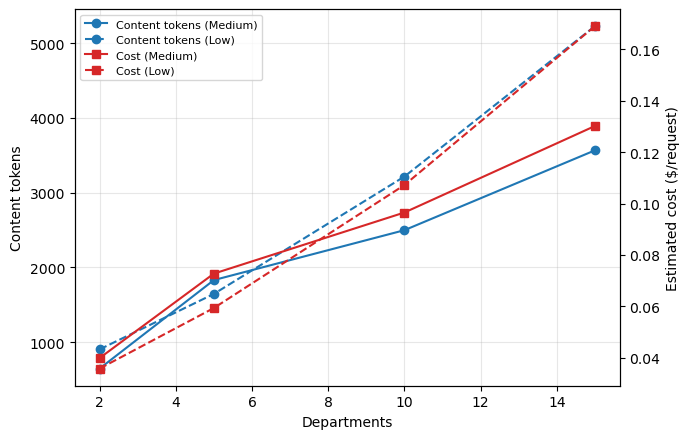

In [19]:
df = pd.DataFrame({
    "departments": [2, 5, 10, 15],
    "content_medium": [644, 1829, 2497, 3566],
    "content_low":    [901, 1644, 3215, 5229],
    "cost_medium": [0.0398, 0.0727, 0.0965, 0.1302],
    "cost_low":    [0.0357, 0.0593, 0.1072, 0.1691],
})

fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(df.departments, df.content_medium, marker='o', color='#1f77b4', label='Content tokens (Medium)')
ax1.plot(df.departments, df.content_low, marker='o', color='#1f77b4', linestyle='--', label='Content tokens (Low)')
ax1.set_xlabel("Departments")
ax1.set_ylabel("Content tokens")

ax2 = ax1.twinx()
ax2.plot(df.departments, df.cost_medium, marker='s', color='#d62728', label='Cost (Medium)')
ax2.plot(df.departments, df.cost_low, marker='s', color='#d62728', linestyle='--', label='Cost (Low)')
ax2.set_ylabel("Estimated cost ($/request)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=8)
ax1.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Prompt Clarity & Escalation Rate

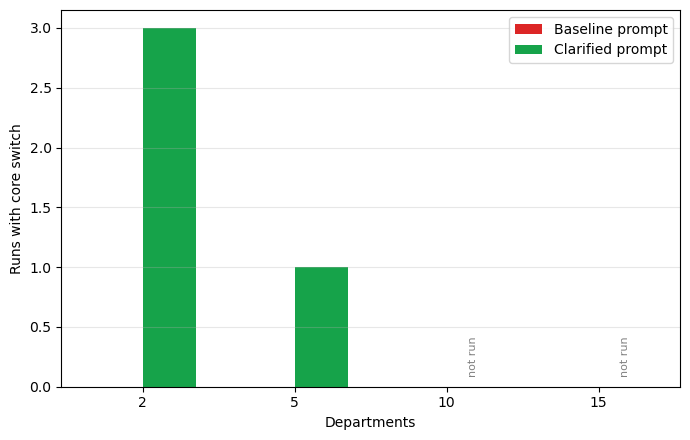

In [21]:


departments = ["2", "5", "10", "15"]
baseline_core = [0, 0, 0, 0]         
Clarified = [3, 1, None, None]  

x = np.arange(len(departments))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width/2, baseline_core, width, label='Baseline prompt', color='#DC2626')
sharp_vals = [v if v is not None else 0 for v in Clarified]
sharp_present = [v is not None for v in Clarified]
bars = ax.bar(x + width/2, sharp_vals, width, label='Clarified prompt', color='#16A34A')
for i, present in enumerate(sharp_present):
    if not present:
        ax.text(x[i] + width/2, 0.1, "not run", ha='center', fontsize=8, rotation=90, color='gray')

ax.set_xticks(x)
ax.set_xticklabels(departments)
ax.set_xlabel("Departments")
ax.set_ylabel("Runs with core switch")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()